# Funding, fear, and greed

This notebook rebuilds the September 2024 post, then repeats the same study on the later data and on the full history.

Run every cell from top to bottom. The three windows are separate sections. Each section has its own t-tests, its own histograms, and its own charts. A figure never mixes the three windows.

- Original window: 21 January 2020 through 9 September 2024. This is the post.
- New stretch: 10 September 2024 through the last day with funding and a following close.
- Full history: both stretches together.

On the original window the rounded figures match the screenshot:

- extreme fear, index < 20: T = −0.32, p = 0.75
- extreme greed, index > 70: T = 1.2, p = 0.22
- negative funding: T = 2.1, p = 0.035
- mean next-day return 0.75% versus 0.09% when funding is positive

The screenshot caption says the greed threshold is "index > 80". The figures 1.2 and 0.22 come from a threshold of 70. A threshold of 80 is a different test, about T = 1.7 and p = 0.08.

This describes a test that has already been run. It is not investment advice.


## Parameters

`POST_END` closes the post window. `END = None` takes history through the last day that has both funding and the next BTC-USD close.


In [1]:
# September 2024 post window. The post text uses only this window.
START = "2020-01-21"
POST_END = "2024-09-09"

# End of the updated history. None means the last day shared by price and funding.
END = None

# Extreme fear and extreme greed. Used by the post text.
FEAR_BELOW = 20
GREED_ABOVE = 70

# Local snapshots used when a source does not respond.
DATA_DIR = "data"


## What is being compared

Each day t contributes three numbers:

- the daily BTC-USD close;
- the fear and greed index for that UTC day;
- the last 8-hour funding print of the Binance BTCUSDT perpetual on that UTC day.

Next-day return is `close(t+1) / close(t) - 1`. The test is Welch's t-test: variances are not assumed equal. The group's mean and variance are compared with the mean and variance of every day in that same window, including the group itself. The old notebook ran several versions of the t-test. This is the one that went into the post. A second table in each section compares the group with the other days only. Those p-values were not in the post.

Thresholds: index < 20, index > 70, funding <= 0, and funding >= 0. A day with funding exactly equal to 0 would fall into both funding groups. This series has no such day.

The original window recomputes the return inside its own rows, so 9 September 2024 has an empty return and is still counted. That is how the published T and p were built. The new stretch and the full history take the next close from the price series, so a boundary day keeps its return when the next close exists.


In [2]:
from __future__ import annotations

import io
import zipfile
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import yfinance as yf
from IPython.display import Image, display
from scipy import stats

plt.rcParams["figure.figsize"] = (11, 4.8)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
plt.rcParams["font.size"] = 12

FUNDING_URL = (
    "https://data.binance.vision/data/futures/um/monthly/fundingRate/"
    "BTCUSDT/BTCUSDT-fundingRate-{month}.zip"
)
SESSION = requests.Session()
SESSION.headers["User-Agent"] = "funding-fear-greed-notebook/1.0"


def month_spans(first: pd.Timestamp, last: pd.Timestamp):
    year, month = first.year, first.month
    while (year, month) <= (last.year, last.month):
        yield year, month
        month += 1
        if month == 13:
            year += 1
            month = 1


def fetch_bytes(url: str) -> requests.Response:
    last_error: Exception | None = None
    for attempt in range(3):
        try:
            response = SESSION.get(url, timeout=60)
        except requests.RequestException as exc:
            last_error = exc
            continue
        if response.status_code in {429, 500, 502, 503, 504} and attempt < 2:
            continue
        return response
    raise RuntimeError(f"Failed to download {url}: {last_error}")


def read_funding_zip(payload: bytes) -> pd.DataFrame:
    archive = zipfile.ZipFile(io.BytesIO(payload))
    frame = pd.read_csv(archive.open(archive.namelist()[0]))
    frame["ts"] = pd.to_datetime(frame["calc_time"], unit="ms", utc=True)
    frame["funding_rate"] = pd.to_numeric(frame["last_funding_rate"])
    frame["date"] = frame["ts"].dt.tz_convert("UTC").dt.normalize().dt.tz_localize(None)
    return frame


def load_funding(data_dir: Path) -> pd.DataFrame:
    path = data_dir / "binance_btcusdt_funding_daily.csv"
    first = pd.Timestamp("2020-01-01")
    last = pd.Timestamp.today().normalize()
    months = list(month_spans(first, last))
    print(f"Binance BTCUSDT funding: {len(months)} monthly files")

    def one(item: tuple[int, int]):
        year, month = item
        label = f"{year:04d}-{month:02d}"
        response = fetch_bytes(FUNDING_URL.format(month=label))
        return label, response.status_code, response.content

    try:
        with ThreadPoolExecutor(max_workers=8) as pool:
            downloaded = list(pool.map(one, months))
    except Exception as exc:
        if not path.exists():
            raise
        print(f"Binance archive did not respond ({exc}). Using snapshot {path}.")
        cached = pd.read_csv(path, parse_dates=["date"])
        return cached

    frames = []
    ok_months = []
    missing_months = []
    for label, status, payload in downloaded:
        if status == 404:
            missing_months.append(label)
            continue
        if status != 200:
            if path.exists():
                print(f"{label}: HTTP {status}. Using snapshot {path}.")
                return pd.read_csv(path, parse_dates=["date"])
            raise RuntimeError(f"Funding {label}: HTTP {status}")
        ok_months.append(label)
        frames.append(read_funding_zip(payload))
    if ok_months:
        holes = [label for label in missing_months if label < ok_months[-1]]
        if holes:
            print("Missing months inside the history:", ", ".join(holes))

    if not frames:
        if path.exists():
            print(f"Empty archive response. Using snapshot {path}.")
            return pd.read_csv(path, parse_dates=["date"])
        raise RuntimeError("Binance returned no funding months.")

    prints = pd.concat(frames, ignore_index=True)
    daily = (
        prints.sort_values("ts")
        .groupby("date", as_index=False)
        .agg(funding_rate=("funding_rate", "last"))
    )
    data_dir.mkdir(parents=True, exist_ok=True)
    daily.to_csv(path, index=False)
    print(
        f"Funding {daily['date'].min().date()} — {daily['date'].max().date()}: "
        f"{len(daily)} days"
    )
    return daily


def load_fear_greed(data_dir: Path) -> pd.DataFrame:
    path = data_dir / "fear_greed.csv"
    try:
        response = fetch_bytes("https://api.alternative.me/fng/?limit=0&format=json")
        response.raise_for_status()
        rows = []
        for entry in response.json()["data"]:
            stamp = pd.to_datetime(int(entry["timestamp"]), unit="s", utc=True)
            day = stamp.tz_convert("UTC").normalize().tz_localize(None)
            rows.append((day, int(entry["value"])))
        frame = pd.DataFrame(rows, columns=["date", "fear_greed"])
        frame = frame.drop_duplicates("date").sort_values("date")
        data_dir.mkdir(parents=True, exist_ok=True)
        frame.to_csv(path, index=False)
    except Exception as exc:
        if not path.exists():
            raise
        print(f"Fear and greed index did not respond ({exc}). Using snapshot {path}.")
        frame = pd.read_csv(path, parse_dates=["date"])
    print(
        f"Index {frame['date'].min().date()} — {frame['date'].max().date()}: "
        f"{len(frame)} days"
    )
    return frame


def normalize_price(raw: pd.DataFrame) -> pd.DataFrame:
    if raw is None or len(raw) == 0:
        raise RuntimeError("Yahoo Finance returned an empty BTC-USD series.")
    if isinstance(raw.columns, pd.MultiIndex):
        raw = raw.copy()
        raw.columns = raw.columns.get_level_values(0)
    close = raw[["Close"]].copy()
    index = pd.to_datetime(close.index)
    if getattr(index, "tz", None) is not None:
        index = index.tz_convert("UTC").tz_localize(None)
    close.index = index.normalize()
    frame = close.reset_index()
    date_column = "Date" if "Date" in frame.columns else frame.columns[0]
    frame = frame.rename(columns={date_column: "date", "Close": "close"})
    frame["date"] = pd.to_datetime(frame["date"]).dt.normalize()
    return frame.drop_duplicates("date").sort_values("date")


def load_btc(start: pd.Timestamp, end: pd.Timestamp, data_dir: Path) -> pd.DataFrame:
    path = data_dir / "btc_usd_daily.csv"
    try:
        wide_end = (pd.Timestamp.today().normalize() + pd.Timedelta(days=1)).strftime("%Y-%m-%d")
        raw = yf.download(
            "BTC-USD",
            start="2020-01-01",
            end=wide_end,
            auto_adjust=False,
            progress=False,
        )
        frame = normalize_price(raw)
        data_dir.mkdir(parents=True, exist_ok=True)
        frame.to_csv(path, index=False)
    except Exception as exc:
        if not path.exists():
            raise
        print(f"Yahoo Finance did not respond ({exc}). Using snapshot {path}.")
        frame = pd.read_csv(path, parse_dates=["date"])
    window = frame[(frame["date"] >= start) & (frame["date"] <= end)].copy()
    if window.empty:
        raise RuntimeError("The BTC-USD series has no days inside the selected window.")
    print(f"BTC-USD {window['date'].min().date()} — {window['date'].max().date()}: {len(window)} days")
    return window[["date", "close"]]


## Build the three windows

The cells below only cut the history. The t-tests, histograms, and charts for each window come later, in their own sections.


In [3]:
data_dir = Path(DATA_DIR)
start = pd.Timestamp(START)
post_end = pd.Timestamp(POST_END)
latest_request = None if END in (None, "") else pd.Timestamp(END)

funding = load_funding(data_dir)
fear = load_fear_greed(data_dir)
price_end = pd.Timestamp.today().normalize()
if latest_request is not None:
    price_end = min(price_end, latest_request)
btc = load_btc(start, price_end, data_dir).sort_values("date").drop_duplicates("date")
btc["forward_return"] = btc["close"].pct_change().shift(-1)

history = (
    btc.merge(funding, on="date", how="inner")
    .merge(fear, on="date", how="left")
    .sort_values("date")
)
history = history[history["date"] >= start]
if latest_request is not None:
    history = history[history["date"] <= latest_request]
history = history.dropna(subset=["close", "funding_rate", "forward_return"]).reset_index(drop=True)


def attach_return(frame: pd.DataFrame, inside_window: bool) -> pd.DataFrame:
    out = frame.sort_values("date").reset_index(drop=True).copy()
    if inside_window:
        # Last day of this frame has no following close inside the frame.
        out["next_day_return"] = out["close"].pct_change().shift(-1)
    else:
        out["next_day_return"] = out["forward_return"]
    out["extreme_fear"] = out["fear_greed"] < FEAR_BELOW
    out["extreme_greed"] = out["fear_greed"] > GREED_ABOVE
    out["negative_funding"] = out["funding_rate"] <= 0
    out["positive_funding"] = out["funding_rate"] >= 0
    return out


# September 2024 post. Dropping a missing index does not remove any day in this window.
sample = attach_return(history[history["date"] <= post_end].dropna(subset=["fear_greed"]), True)
new_stretch = attach_return(history[history["date"] > post_end], False)
full_history = attach_return(history, False)


def describe(name: str, frame: pd.DataFrame) -> None:
    missing_index = int(frame["fear_greed"].isna().sum())
    print(
        f"{name} {frame['date'].min().date()} — {frame['date'].max().date()}: "
        f"{len(frame)} days, funding < 0: {int(frame['negative_funding'].sum())}, "
        f"fear: {int(frame['extreme_fear'].sum())}, greed: {int(frame['extreme_greed'].sum())}, "
        f"days without an index: {missing_index}"
    )


describe("Original window", sample)
describe("New stretch", new_stretch)
describe("Full history", full_history)
sample[["date", "close", "fear_greed", "funding_rate", "next_day_return"]].tail(3)


Binance BTCUSDT funding: 82 monthly files


Funding 2020-01-01 — 2026-09-30: 2465 days


Index 2018-02-01 — 2026-10-21: 3181 days


BTC-USD 2020-01-21 — 2026-10-21: 2466 days
Original window 2020-01-21 — 2024-09-09: 1694 days, funding < 0: 206, fear: 138, greed: 413, days without an index: 0
New stretch 2024-09-10 — 2026-09-30: 751 days, funding < 0: 119, fear: 113, greed: 157, days without an index: 1
Full history 2020-01-21 — 2026-09-30: 2445 days, funding < 0: 325, fear: 251, greed: 570, days without an index: 1


,date,close,fear_greed,funding_rate,next_day_return
1691,2024-09-07,54139.687500,23.0,-0.000072,0.012964
1692,2024-09-08,54841.566406,29.0,-0.000052,0.039714
1693,2024-09-09,57019.535156,26.0,-0.000039,NaN


## Shared calculations

Welch's t-test, the histogram, and the two charts are defined once. Each window below calls them on its own rows. A call never receives the other two windows.


In [4]:
def welch(group: pd.Series, group_nobs: int, reference: pd.Series, reference_nobs: int):
    t_stat, p_value = stats.ttest_ind_from_stats(
        mean1=group.mean(),
        std1=group.std(ddof=1),
        nobs1=group_nobs,
        mean2=reference.mean(),
        std2=reference.std(ddof=1),
        nobs2=reference_nobs,
        equal_var=False,
    )
    return float(t_stat), float(p_value)


def show_table(frame: pd.DataFrame, percent_columns: list[str]) -> None:
    view = frame.copy()
    for column in percent_columns:
        view[column] = view[column].map(lambda value: f"{value:.2%}")
    for column in ("t", "p"):
        view[column] = view[column].map(lambda value: f"{value:.4f}")
    display(view)


def show_figure(figure: plt.Figure) -> None:
    buffer = io.BytesIO()
    figure.savefig(buffer, format="png", dpi=140, bbox_inches="tight", facecolor="white")
    display(Image(data=buffer.getvalue()))
    plt.close(figure)


def conditions(frame: pd.DataFrame):
    return [
        (f"Fear, index < {FEAR_BELOW}", frame["extreme_fear"], "#2f6f9f"),
        (f"Greed, index > {GREED_ABOVE}", frame["extreme_greed"], "#c47b2b"),
        ("Negative funding", frame["negative_funding"], "#b42318"),
        ("Positive funding", frame["positive_funding"], "#1f7a4d"),
    ]


def row_against_sample(frame: pd.DataFrame, name: str, mask: pd.Series) -> dict:
    group = frame.loc[mask, "next_day_return"]
    t_stat, p_value = welch(group, int(mask.sum()), frame["next_day_return"], len(frame))
    return {
        "condition": name,
        "days": int(mask.sum()),
        "mean next-day return": group.mean(),
        "t": t_stat,
        "p": p_value,
    }


def row_against_rest(frame: pd.DataFrame, name: str, mask: pd.Series) -> dict:
    group = frame.loc[mask, "next_day_return"]
    rest = frame.loc[~mask, "next_day_return"]
    t_stat, p_value = welch(group, int(mask.sum()), rest, int((~mask).sum()))
    return {
        "condition": name,
        "days": int(mask.sum()),
        "mean in group": group.mean(),
        "mean on other days": rest.mean(),
        "t": t_stat,
        "p": p_value,
    }


def study_tables(frame: pd.DataFrame, versus_sample: str, versus_rest: str) -> pd.DataFrame:
    rows = [(name, mask) for name, mask, _color in conditions(frame)]
    published_here = pd.DataFrame([row_against_sample(frame, name, mask) for name, mask in rows])
    published_here["significant at 5%"] = published_here["p"] < 0.05
    rest_here = pd.DataFrame([row_against_rest(frame, name, mask) for name, mask in rows])
    print(versus_sample)
    show_table(published_here, ["mean next-day return"])
    print(versus_rest)
    show_table(rest_here, ["mean in group", "mean on other days"])
    return published_here


HIST_LIMIT = 0.10


def plot_histograms(frame: pd.DataFrame, window_name: str) -> None:
    bins = np.linspace(-HIST_LIMIT, HIST_LIMIT, 41)
    returns = frame["next_day_return"].dropna()
    outside = int(((returns < -HIST_LIMIT) | (returns > HIST_LIMIT)).sum())
    print(
        f"{window_name}: {outside} days fall outside −10% to 10% and are not drawn. "
        "They stay in the t-tests."
    )

    figure, axes = plt.subplots(1, 2, figsize=(11, 4.4), sharey=True)
    panels = [
        (
            axes[0],
            "Funding",
            [
                (frame.loc[frame["positive_funding"], "next_day_return"], "Funding > 0", "#1f7a4d"),
                (frame.loc[frame["negative_funding"], "next_day_return"], "Funding ≤ 0", "#b42318"),
            ],
        ),
        (
            axes[1],
            "Fear and greed",
            [
                (
                    frame.loc[frame["extreme_fear"], "next_day_return"],
                    f"Fear, index < {FEAR_BELOW}",
                    "#2f6f9f",
                ),
                (
                    frame.loc[frame["extreme_greed"], "next_day_return"],
                    f"Greed, index > {GREED_ABOVE}",
                    "#c47b2b",
                ),
            ],
        ),
    ]
    for axis, panel_name, groups in panels:
        for series, label, color in groups:
            clean = series.dropna()
            axis.hist(
                clean,
                bins=bins,
                density=True,
                alpha=0.55,
                color=color,
                label=f"{label}, mean {clean.mean():.2%}",
            )
            axis.axvline(clean.mean(), color=color, lw=1.2, ls="--")
        axis.axvline(0, color="#1f2933", lw=0.8)
        axis.set_xlim(-HIST_LIMIT, HIST_LIMIT)
        axis.xaxis.set_major_formatter(plt.FuncFormatter(lambda value, _pos: f"{value:.0%}"))
        axis.set_xlabel("Next-day return")
        axis.set_title(panel_name)
        axis.legend(frameon=False, fontsize=9)
    axes[0].set_ylabel("Density")
    figure.suptitle(f"{window_name}: distribution of the next-day return", fontsize=13)
    figure.tight_layout()
    show_figure(figure)


def plot_mean_bars(frame: pd.DataFrame, window_name: str) -> None:
    means = [("Full sample", frame["next_day_return"].mean(), "#52606d")]
    means.extend(
        (name, frame.loc[mask, "next_day_return"].mean(), color)
        for name, mask, color in conditions(frame)
    )
    labels = [item[0] for item in means]
    values = [item[1] * 100 for item in means]
    colors = [item[2] for item in means]
    figure, axis = plt.subplots()
    positions = np.arange(len(labels))
    bars = axis.barh(positions, values, color=colors, height=0.72)
    axis.axvline(0, color="#1f2933", lw=0.8)
    axis.set_yticks(positions, labels)
    axis.set_xlabel("Mean next-day return, %")
    axis.set_title(f"{window_name}: mean next-day return")
    axis.invert_yaxis()
    span = max(values) - min(0, min(values))
    pad = max(0.12, span * 0.22)
    for bar, value in zip(bars, values):
        axis.text(
            value + pad * 0.08,
            bar.get_y() + bar.get_height() / 2,
            f"{value:.2f}%",
            va="center",
            ha="left",
            color="#1f2933",
        )
    axis.set_xlim(min(0, min(values) - pad), max(values) + pad)
    figure.tight_layout()
    show_figure(figure)


def plot_price(frame: pd.DataFrame, window_name: str) -> None:
    figure, axis = plt.subplots()
    axis.plot(frame["date"], frame["close"], color="#1f2933", lw=1.1, label="BTC-USD")
    negative = frame[frame["negative_funding"]]
    axis.scatter(
        negative["date"],
        negative["close"],
        s=16,
        color="#b42318",
        zorder=3,
        label="Funding ≤ 0",
    )
    axis.set_yscale("log")
    axis.set_ylabel("Close, log scale")
    axis.set_title(f"{window_name}: negative-funding days")
    axis.legend(frameon=False, loc="upper left")
    figure.tight_layout()
    show_figure(figure)


## Original window, 21 January 2020 – 9 September 2024

This is the post window. The next-day return is recomputed inside these rows, so 9 September 2024 has an empty return and is still counted in the number of days. The first table is the comparison printed in the post.


In [5]:
published = study_tables(
    sample,
    "Group versus the full sample. These rows build the post.",
    "Group versus the other days. These p-values were not in the post.",
)


Group versus the full sample. These rows build the post.


,condition,days,mean next-day return,t,p,significant at 5%
0,"Fear, index < 20",138,0.02%,-0.3225,0.7476,False
1,"Greed, index > 70",413,0.40%,1.2087,0.2272,False
2,Negative funding,206,0.75%,2.1102,0.0358,True
3,Positive funding,1488,0.09%,-0.6671,0.5048,False


Group versus the other days. These p-values were not in the post.


,condition,days,mean in group,mean on other days,t,p
0,"Fear, index < 20",138,0.02%,0.18%,-0.3514,0.7258
1,"Greed, index > 70",413,0.40%,0.10%,1.5561,0.1201
2,Negative funding,206,0.75%,0.09%,2.3902,0.0176
3,Positive funding,1488,0.09%,0.75%,-2.3902,0.0176


### Histograms, original window

Next-day returns on this window only. The left panel is funding. The right panel is fear and greed. Dashed lines are the group means. Days outside −10% to 10% stay in the tests and are left off the axis.


Original window: 31 days fall outside −10% to 10% and are not drawn. They stay in the t-tests.


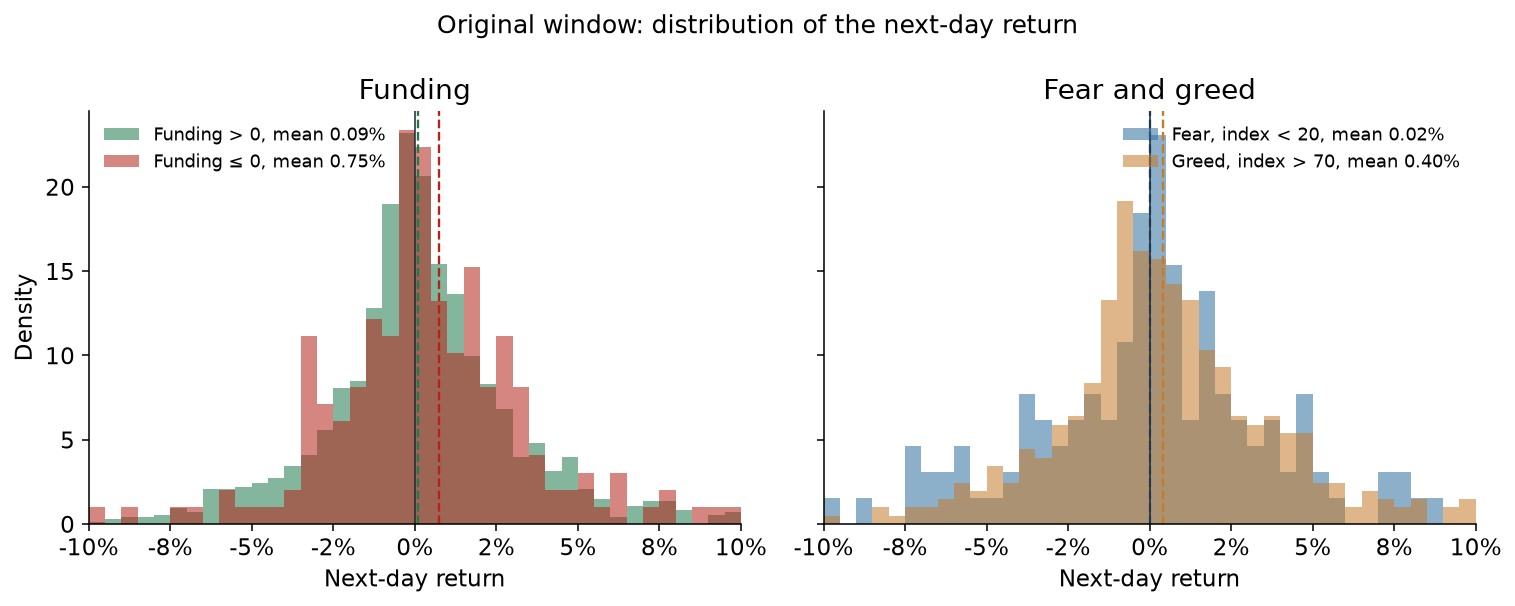

In [6]:
plot_histograms(sample, "Original window")


### Charts, original window

Mean next-day return by condition, then the Bitcoin price with the negative-funding days marked. Both use only the original window.


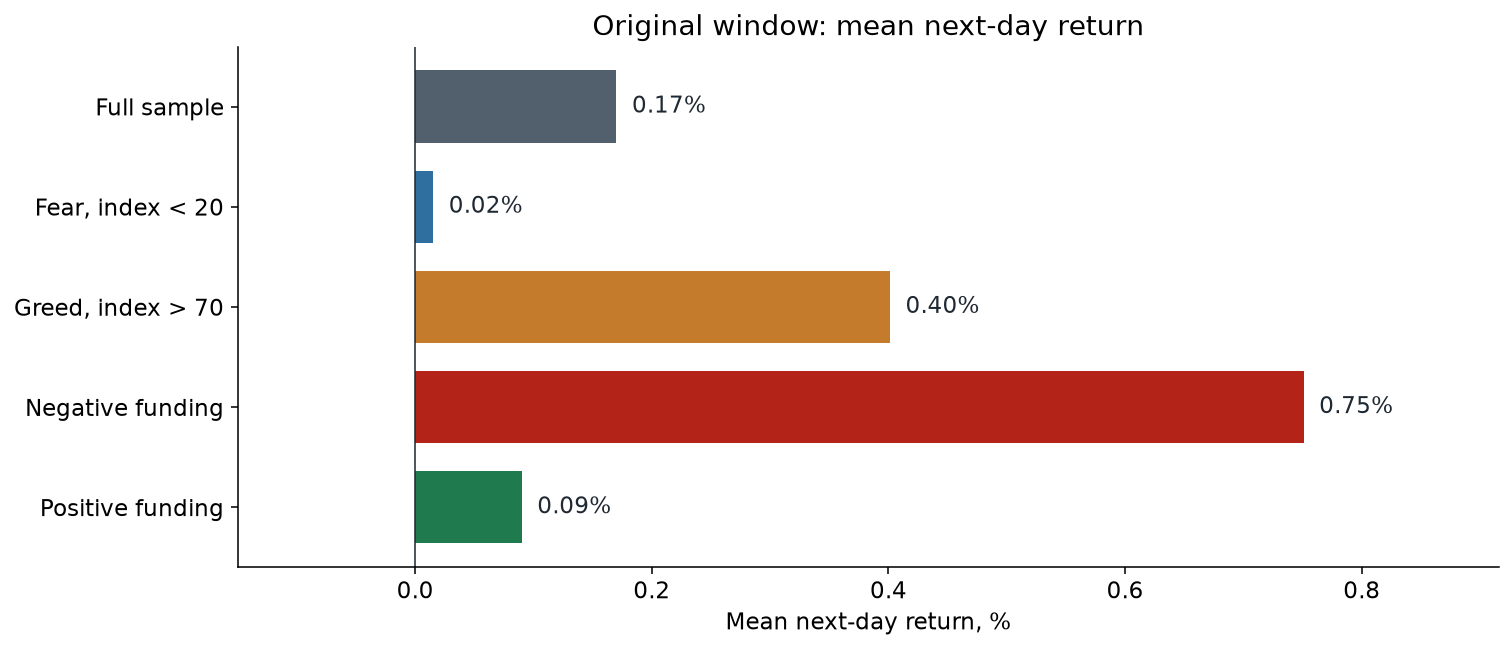

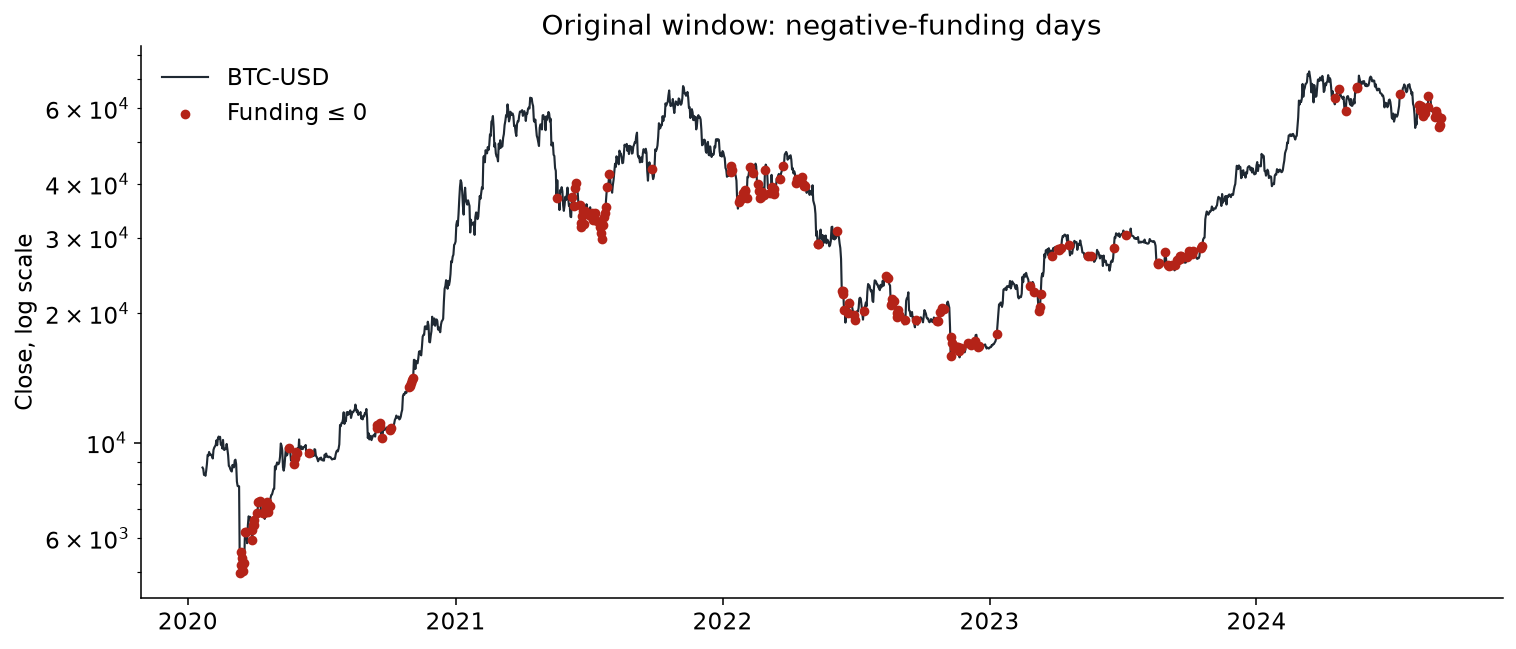

In [7]:
plot_mean_bars(sample, "Original window")
plot_price(sample, "Original window")


### Post text, original window

The numbers below are rounded the way the screenshot rounded them. A t-statistic of 1 or more is shown with one decimal place, and a smaller one with two. A p-value below 0.05 is cut to three digits: 0.0358 was written as 0.035.

The greed p-value in the table is about 0.227. Ordinary rounding to two digits gives 0.23. The screenshot says 0.22, and the post text for this window keeps 0.22.

"8 times" is the ratio of the already rounded percentages 0.75 and 0.09.


In [8]:
def post_t(value: float) -> str:
    if abs(value) >= 1:
        return f"{value:.1f}"
    return f"{value:.2f}"


def post_p(value: float) -> str:
    if value < 0.05:
        # The post wrote 0.0358 as 0.035: it kept three digits and dropped the rest.
        truncated = int(value * 1000) / 1000
        return f"{truncated:.3f}"
    return f"{value:.2f}"


def percent_label(mean: float) -> str:
    return f"{mean * 100:.2f}%"


by_name = {row["condition"]: row for row in published.to_dict("records")}
fear = by_name[f"Fear, index < {FEAR_BELOW}"]
greed = by_name[f"Greed, index > {GREED_ABOVE}"]
negative = by_name["Negative funding"]
positive = by_name["Positive funding"]


def fear_verdict(result: dict) -> str:
    if result["p"] >= 0.05:
        return "Price behaves as usual. Sorry, Buffett!"
    if result["t"] > 0:
        return "Fear days are followed by a larger next-day rise than the sample average."
    return "Fear days are followed by a weaker next-day return than the sample average."


def greed_verdict(result: dict) -> str:
    if result["p"] >= 0.05:
        return "No magic here either. Just normal price behavior."
    if result["t"] > 0:
        return "Greed days are followed by a larger next-day rise than the sample average."
    return "Greed days are followed by a weaker next-day return than the sample average."


def funding_verdict(result: dict) -> str:
    if result["p"] < 0.05 and result["t"] > 0:
        return "BINGO! Statistically significant daily price change increase!"
    if result["p"] < 0.05:
        return "Statistically significant, but the next-day return is lower than the sample average."
    return "No statistically significant difference from the sample average."


negative_pct = round(negative["mean next-day return"] * 100, 2)
positive_pct = round(positive["mean next-day return"] * 100, 2)
if positive_pct > 0 and negative_pct > 0:
    times = round(negative_pct / positive_pct)
    insight = (
        f"Key Insight: With negative funding, price daily rises on average by "
        f"{negative_pct:.2f}%, which is {times} times more than with positive funding "
        f"({positive_pct:.2f}%)!"
    )
else:
    times = None
    insight = (
        "Key Insight: Average next-day return is "
        f"{percent_label(negative['mean next-day return'])} after negative funding "
        f"and {percent_label(positive['mean next-day return'])} after positive funding."
    )

published_window = (
    str(START) == "2020-01-21"
    and str(POST_END) == "2024-09-09"
    and FEAR_BELOW == 20
    and GREED_ABOVE == 70
)
# The screenshot writes the greed p-value as 0.22. The raw value is about 0.227;
# ordinary rounding to two digits gives 0.23. The post text for the original window
# keeps the screenshot figure. The exact p-value is in the table above.
greed_p_text = "0.22" if published_window else post_p(greed["p"])

bingo = negative["p"] < 0.05 and negative["t"] > 0
spoiler = (
    "(Spoiler: negative funding is our bro!)"
    if bingo
    else "(Spoiler: the old slogan does not survive this window.)"
)
conclusion = (
    "Conclusion: Hamsters, prepare to be sheared! Negative funding is our "
    "true friend in the crypto trading world."
    if bingo
    else "Conclusion: On this window the negative-funding slogan from the old post does not hold."
)

start_label = sample["date"].min().date().isoformat()
end_label = sample["date"].max().date().isoformat()
post = f'''FEAR & GREED INDEX vs FUNDING RATE: BATTLE OF THE TITANS!

"Be fearful when others are greedy and greedy when others are fearful" - Warren Buffett
"Mass shorts = liquidation of hamsters" - Crypto traders

Let's test these claims with t-tests from math stats!
{spoiler}

Extreme Fear (index < {FEAR_BELOW}):
T-stats: {post_t(fear["t"])}, P-value: {post_p(fear["p"])}
Verdict: {fear_verdict(fear)}

Extreme Greed (index > {GREED_ABOVE}):
T-stats: {post_t(greed["t"])}, P-value: {greed_p_text}
Verdict: {greed_verdict(greed)}

Negative Funding (funding rate < 0):
T-stats: {post_t(negative["t"])}, P-value: {post_p(negative["p"])}
Verdict: {funding_verdict(negative)}

{insight}

{conclusion}

#Cryptocurrencies #Bitcoin #TradingStrategies #DataScience #Trading #fintech #cryptoinvesting #crypto #investingtips #cryptotip

P.S. Data {start_label} to {end_label}. Funding from Binance BTCUSDT perpetual (last print of each UTC day), fear and greed index from alternative.me. Each t-test compares next-day BTC-USD returns on the selected days with the average next-day return of the whole sample. Not investment advice, DYOR!
'''
print(post)

expected = {
    "fear": ("-0.32", "0.75"),
    "greed": ("1.2", "0.22"),
    "funding": ("2.1", "0.035"),
    "negative_return": "0.75%",
    "positive_return": "0.09%",
    "times": 8,
}
actual = {
    "fear": (post_t(fear["t"]), post_p(fear["p"])),
    "greed": (post_t(greed["t"]), greed_p_text),
    "funding": (post_t(negative["t"]), post_p(negative["p"])),
    "negative_return": f"{negative_pct:.2f}%",
    "positive_return": f"{positive_pct:.2f}%",
    "times": times,
}
if published_window:
    mismatches = {key: (actual[key], expected[key]) for key in expected if actual[key] != expected[key]}
    if mismatches:
        print("Post check failed:", mismatches)
    else:
        print("Post check: every rounded figure matches.")
    print(
        f"Greed p-value in the table: {greed['p']:.4f}. "
        "The screenshot writes 0.22; rounding to two digits gives 0.23."
    )
else:
    print("Window or thresholds changed, so the September 2024 post check was skipped.")


FEAR & GREED INDEX vs FUNDING RATE: BATTLE OF THE TITANS!

"Be fearful when others are greedy and greedy when others are fearful" - Warren Buffett
"Mass shorts = liquidation of hamsters" - Crypto traders

Let's test these claims with t-tests from math stats!
(Spoiler: negative funding is our bro!)

Extreme Fear (index < 20):
T-stats: -0.32, P-value: 0.75
Verdict: Price behaves as usual. Sorry, Buffett!

Extreme Greed (index > 70):
T-stats: 1.2, P-value: 0.22
Verdict: No magic here either. Just normal price behavior.

Negative Funding (funding rate < 0):
T-stats: 2.1, P-value: 0.035
Verdict: BINGO! Statistically significant daily price change increase!

Key Insight: With negative funding, price daily rises on average by 0.75%, which is 8 times more than with positive funding (0.09%)!

Conclusion: Hamsters, prepare to be sheared! Negative funding is our true friend in the crypto trading world.

#Cryptocurrencies #Bitcoin #TradingStrategies #DataScience #Trading #fintech #cryptoinvesting 

## New stretch, from 10 September 2024

The same four conditions, on the days after the post. The next-day return is the next BTC-USD close, including a close that falls after the last funding print. One day in this stretch, 26 October 2024, has no fear and greed index. It stays in the funding groups and in neither fear nor greed.

These tables and figures are not the post, and they do not include the original window.


In [9]:
new_results = study_tables(
    new_stretch,
    "Group versus every day in the new stretch, including the group.",
    "Group versus the other days in the new stretch.",
)


Group versus every day in the new stretch, including the group.


,condition,days,mean next-day return,t,p,significant at 5%
0,"Fear, index < 20",113,0.04%,-0.1407,0.8883,False
1,"Greed, index > 70",157,0.05%,-0.1335,0.8939,False
2,Negative funding,119,0.29%,0.8533,0.3948,False
3,Positive funding,632,0.04%,-0.3286,0.7425,False


Group versus the other days in the new stretch.


,condition,days,mean in group,mean on other days,t,p
0,"Fear, index < 20",113,0.04%,0.09%,-0.1653,0.8689
1,"Greed, index > 70",157,0.05%,0.09%,-0.1641,0.8698
2,Negative funding,119,0.29%,0.04%,1.0066,0.3157
3,Positive funding,632,0.04%,0.29%,-1.0066,0.3157


### Histograms, new stretch


New stretch: 3 days fall outside −10% to 10% and are not drawn. They stay in the t-tests.


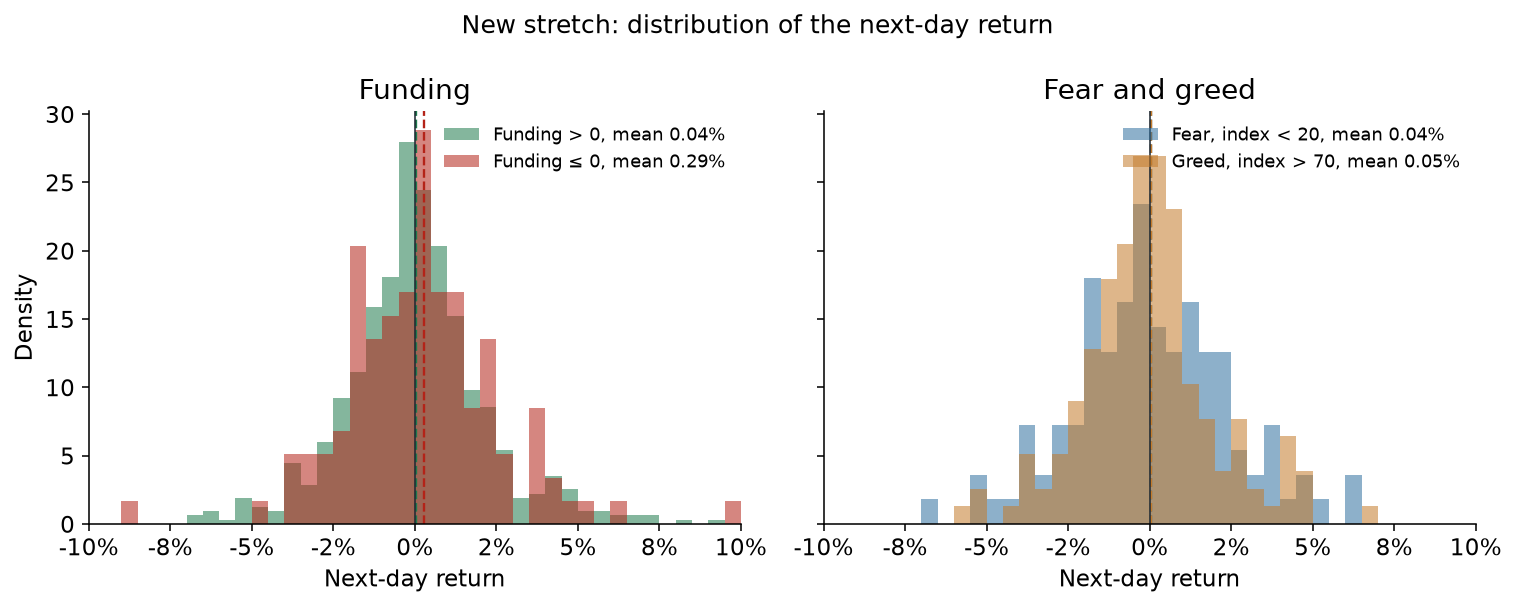

In [10]:
plot_histograms(new_stretch, "New stretch")


### Charts, new stretch


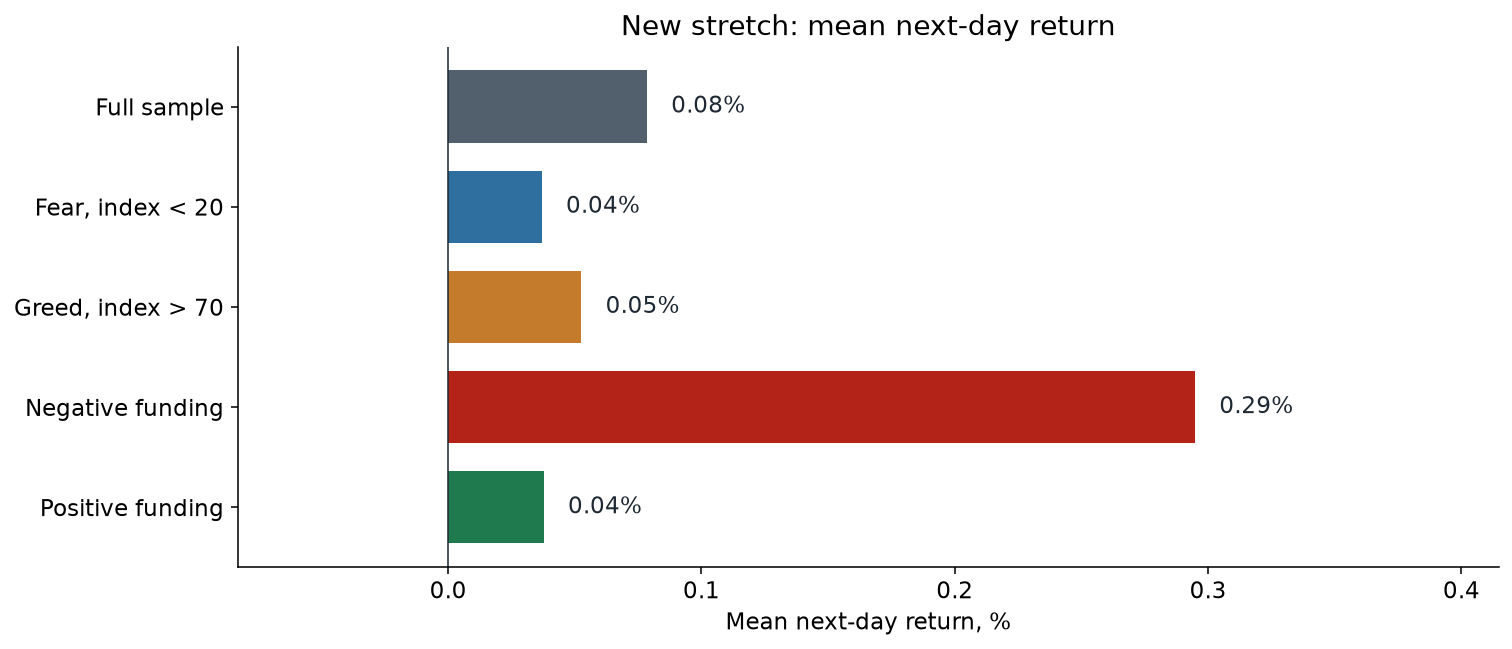

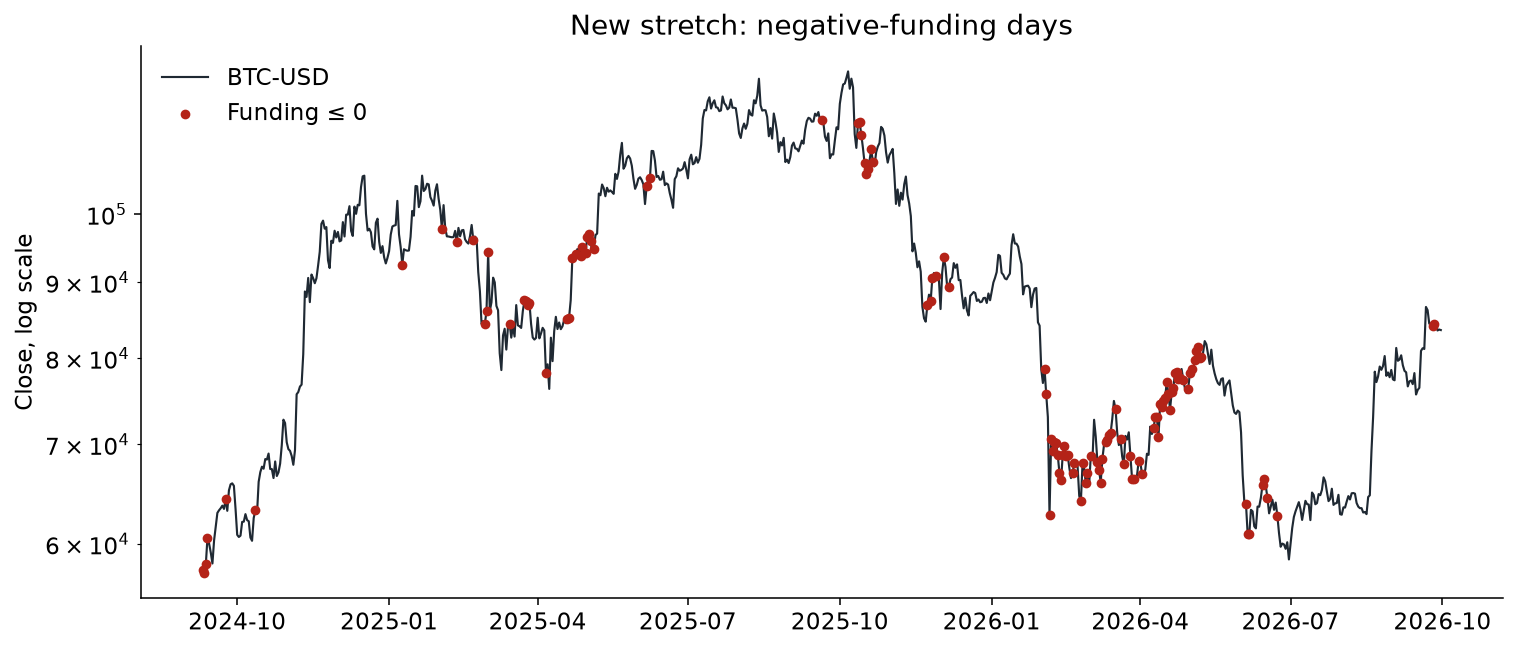

In [11]:
plot_mean_bars(new_stretch, "New stretch")
plot_price(new_stretch, "New stretch")


## Full history

The original window and the new stretch, with no gap and no day counted twice. Unlike the post, 9 September 2024 keeps the close of 10 September, so the negative-funding mean here is not the 0.75% in the post text. The figure shows this window alone.


In [12]:
full_results = study_tables(
    full_history,
    "Group versus every day in the full history, including the group.",
    "Group versus the other days in the full history.",
)


Group versus every day in the full history, including the group.


,condition,days,mean next-day return,t,p,significant at 5%
0,"Fear, index < 20",251,0.02%,-0.3966,0.6920,False
1,"Greed, index > 70",570,0.31%,1.1007,0.2713,False
2,Negative funding,325,0.58%,2.2350,0.0260,True
3,Positive funding,2120,0.07%,-0.7403,0.4592,False


Group versus the other days in the full history.


,condition,days,mean in group,mean on other days,t,p
0,"Fear, index < 20",251,0.02%,0.16%,-0.4423,0.6586
1,"Greed, index > 70",570,0.31%,0.09%,1.4000,0.1619
2,Negative funding,325,0.58%,0.07%,2.5624,0.0108
3,Positive funding,2120,0.07%,0.58%,-2.5624,0.0108


### Histograms, full history


Full history: 34 days fall outside −10% to 10% and are not drawn. They stay in the t-tests.


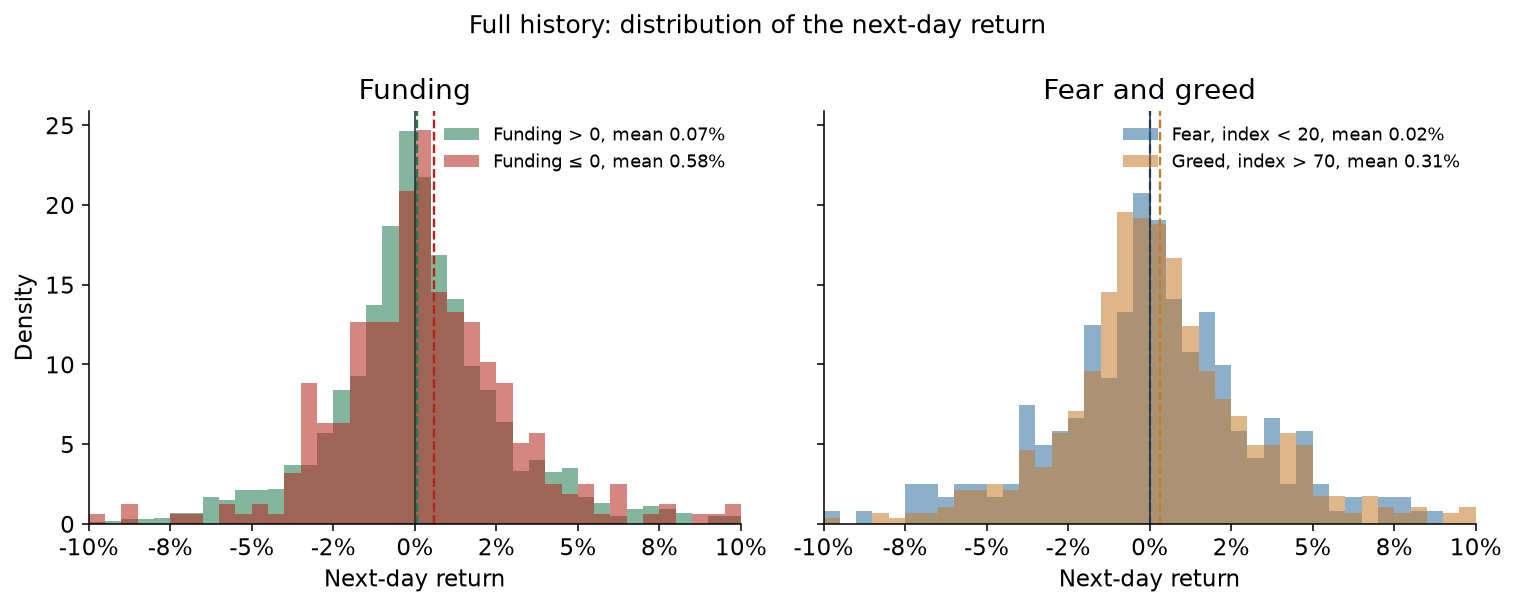

In [13]:
plot_histograms(full_history, "Full history")


### Charts, full history


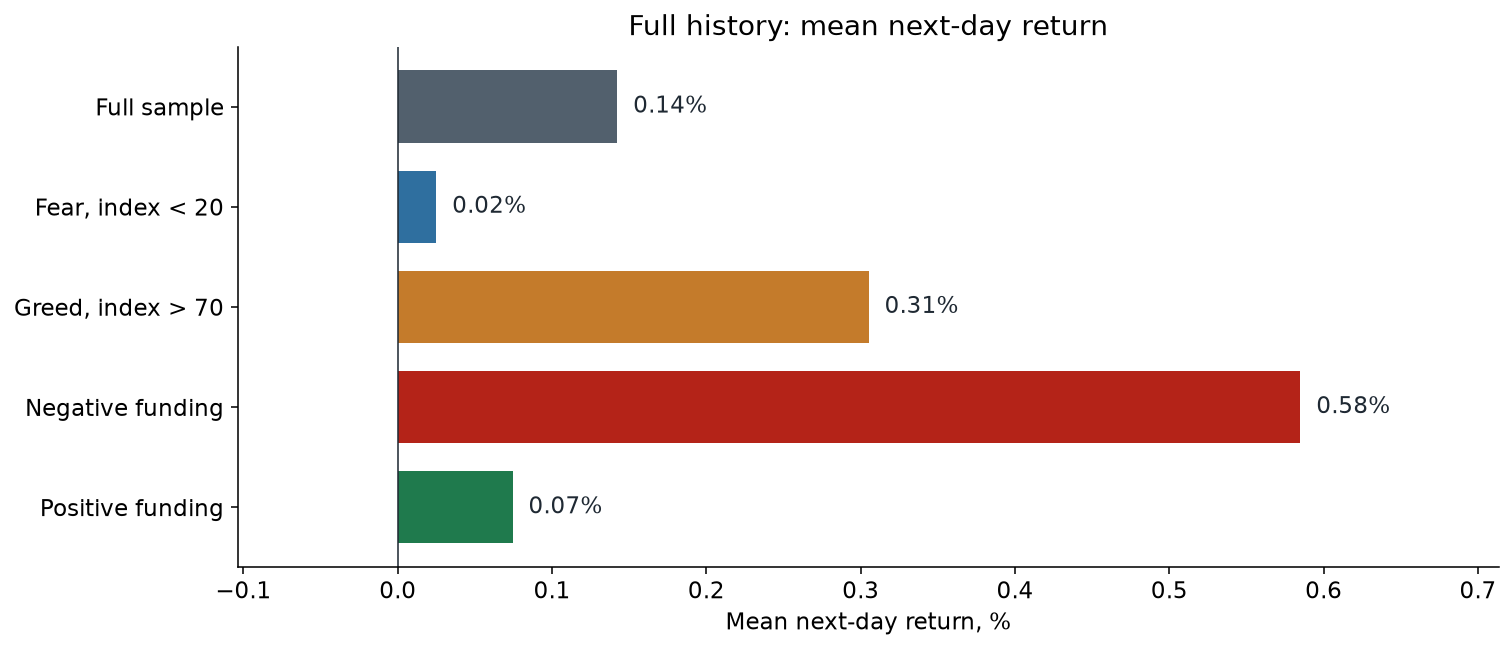

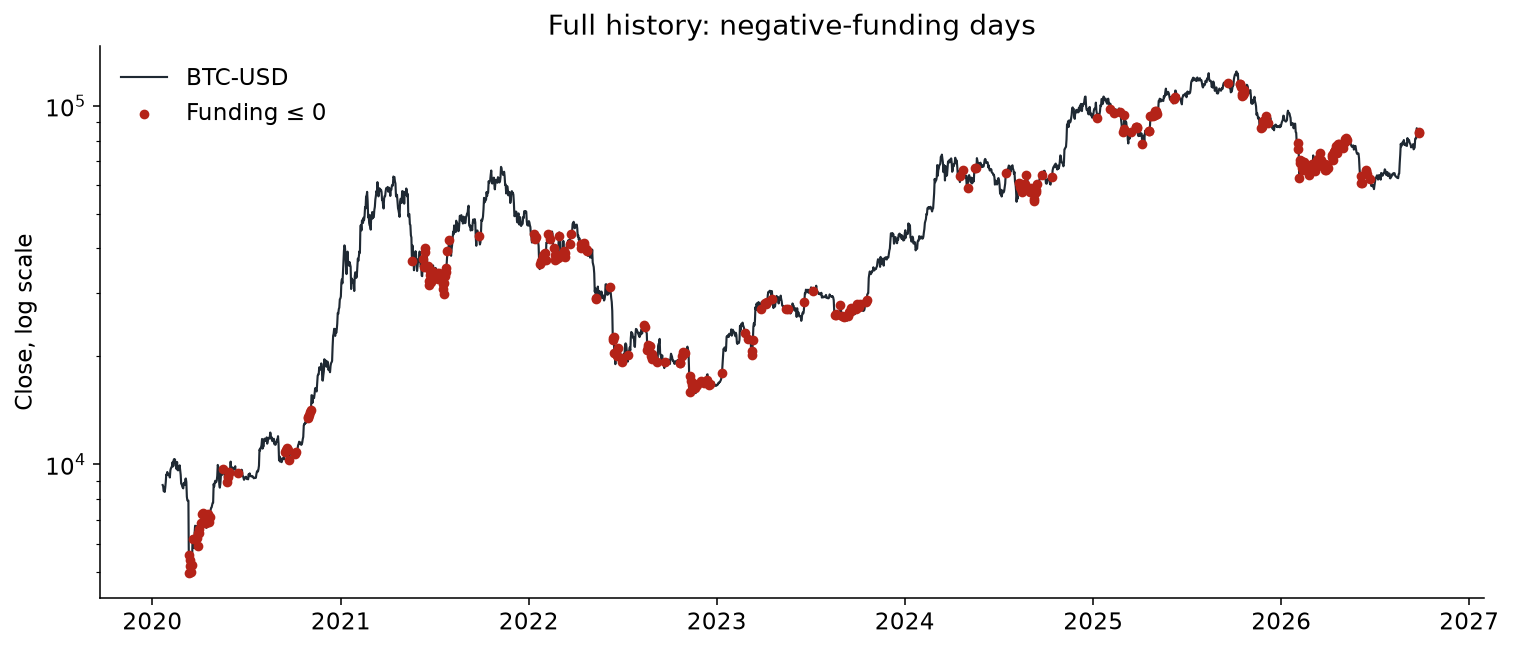

In [14]:
plot_mean_bars(full_history, "Full history")
plot_price(full_history, "Full history")


## What to change next

- A later end of the history shows up on its own: set `END = None` and run the notebook again after Binance publishes the next monthly funding file. The current month usually appears in the archive after the month closes.
- A different greed threshold in the post text: change `GREED_ABOVE`. The value 80 is the screenshot caption, not the threshold that produced 1.2 and 0.22.
- The post text reads the first table of the original window. The second table in each section compares the group with the other days of that same window.
